# 1. Connectivity and fragmentation

**Scientific question.** Do small nearest-neighbour distances imply that the whole school remains connected?

The previous validation established that the social rules, synchronous updates and measurements execute correctly. It also found final groups of 10 + 10 fish for seed 0 and 19 + 1 for seed 2. A local spacing average cannot distinguish one school from several internally compact subgroups.

**Hypotheses.** (A) Local spacing can remain small while whole-group connectivity is lost. (B) The finite social radius can leave multiple disconnected components even when polarization is high. These are diagnostic possibilities, not conclusions about biological fish.

**What changes:** only the measurements added to completed DataCollector records. **What remains controlled:** the shared 2D model, reflecting 20 × 20 BL arena, all three social rules, speed 1 BL/s, `dt=0.125 s`, social range 5.5 BL, and seeds 0–9. No light, parameter tuning, or connectivity feedback is introduced.

**Graph convention.** Every fish is a node. Two fish share an undirected edge when their separation is **≤ 5.5 BL**. A connected component can be a chain; its end fish need not be direct neighbours. This graph describes access through local social links, not physical body contact or demonstrated information transmission.

The local-interaction motivation comes from [Couzin et al. (2002)](https://doi.org/10.1006/jtbi.2002.3065). The selected spatial parameters follow the project's [Puckett et al. (2018)](https://doi.org/10.1038/s41598-018-26037-9) baseline. The connectivity diagnostics are implementation measurements added here.

Use the **mesa-env** kernel and **Restart Kernel → Run All**.


In [1]:
from pathlib import Path
import sys

MODEL_DIR = next(
    folder for parent in (Path.cwd(), *Path.cwd().parents)
    for folder in (parent, parent / "papers")
    if (folder / "shiner_model.py").is_file() and (folder / "handlings").is_dir()
)
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))
HERE = MODEL_DIR / "handlings" / "trial_one"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from types import SimpleNamespace
from IPython.display import Markdown, display
from shiner_model import GoldenShinersModel, compute_group_metrics
from handlings.trial_one.diagnostics import (
    graph_components, run_case, fragmentation_episodes, summarize_case,
)

OUTPUT_DIR = MODEL_DIR / "handlings" / "trial_one"
FIGURE_DIR = OUTPUT_DIR / "figures"
DATA_DIR = OUTPUT_DIR / "data"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
SOCIAL_RANGE = 5.5
PERSISTENCE_S = 2.5
DURATION_S = 62.5
COLORS = {0: "tab:red", 2: "tab:orange", 1: "tab:blue"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)


## First check the graph against known configurations

We construct one group of 20 fish, two groups of 10, and a group of 19 plus one isolated fish. Their expected largest-component fractions are 1.0, 0.5, and 0.95. Each fish points east in these fixed snapshots, so high polarization is deliberately compatible with disconnection.

The connected group and the 10 + 10 configuration use the same 0.2-BL grid spacing. This makes the nearest-neighbour comparison exact rather than relying on a fortunate simulation.


In [2]:
def grid(rows, columns, center, spacing=0.2):
    positions = np.array([(x * spacing, y * spacing) for y in range(rows) for x in range(columns)])
    return positions - positions.mean(axis=0) + np.asarray(center)


connected_positions = grid(4, 5, (10, 10))
two_group_positions = np.vstack([grid(2, 5, (5, 10)), grid(2, 5, (15, 10))])
small_cluster = grid(4, 5, (10, 10))[:19]
isolated_positions = np.vstack([small_cluster, (16, 10)])
known_states = [
    ("One connected group", connected_positions, [20]),
    ("Two compact groups", two_group_positions, [10, 10]),
    ("One isolated fish", isolated_positions, [19, 1]),
]

known_rows = []
for name, positions, expected_sizes in known_states:
    components = graph_components(positions, SOCIAL_RANGE)
    sizes = [len(component) for component in components]
    assert sizes == expected_sizes
    assert sorted(np.concatenate(components).tolist()) == list(range(20))
    measured = compute_group_metrics(SimpleNamespace(agents=[
        SimpleNamespace(position=position, direction=np.array([1.0, 0.0]), speed=1.0)
        for position in positions
    ]))
    known_rows.append({
        "Configuration": name,
        "Expected sizes": "+".join(map(str, expected_sizes)),
        "Observed sizes": "+".join(map(str, sizes)),
        "NumberOfGroups": len(sizes), "LargestGroupSize": sizes[0],
        "LargestGroupFraction": sizes[0] / 20,
        "SecondLargestGroupSize": sizes[1] if len(sizes) > 1 else 0,
        "MeanNND": measured["MeanNND"],
        "MeanDistanceToCentroid": measured["MeanDistanceToCentroid"],
        "Polarization": measured["Polarization"],
    })
known_table = pd.DataFrame(known_rows)
np.testing.assert_allclose(known_table["LargestGroupFraction"], [1.0, 0.5, 0.95])
np.testing.assert_allclose(known_table.loc[:1, "MeanNND"], 0.2)
assert len(graph_components([(0, 0), (5.5, 0)], SOCIAL_RANGE)) == 1
assert len(graph_components([(0, 0), (5.500001, 0)], SOCIAL_RANGE)) == 2
chain = np.column_stack([np.arange(20) * 0.5, np.zeros(20)])
assert len(graph_components(chain, SOCIAL_RANGE)) == 1
assert np.linalg.norm(chain[-1] - chain[0]) > SOCIAL_RANGE
known_table


,Configuration,Expected sizes,Observed sizes,NumberOfGroups,LargestGroupSize,LargestGroupFraction,SecondLargestGroupSize,MeanNND,MeanDistanceToCentroid,Polarization
0,One connected group,20,20,1,20,1.00,0,0.200000,0.339294,1.0
1,Two compact groups,10+10,10+10,2,10,0.50,10,0.200000,5.001003,1.0
2,One isolated fish,19+1,19+1,2,19,0.95,1,0.470045,0.680587,1.0


**Interpretation.** All three component-size answers are recovered. The connected school and the two compact subgroups both have `MeanNND = 0.2 BL`, although their largest-group fractions are 1.0 and 0.5. Both also have polarization 1 because their headings agree. These are explicit counterexamples to using either local spacing or alignment alone as evidence of whole-group cohesion.

The 19 + 1 case keeps most fish close to a neighbour, but one fish is outside the interaction graph. Reporting `SecondLargestGroupSize` helps distinguish this from a balanced 10 + 10 division.


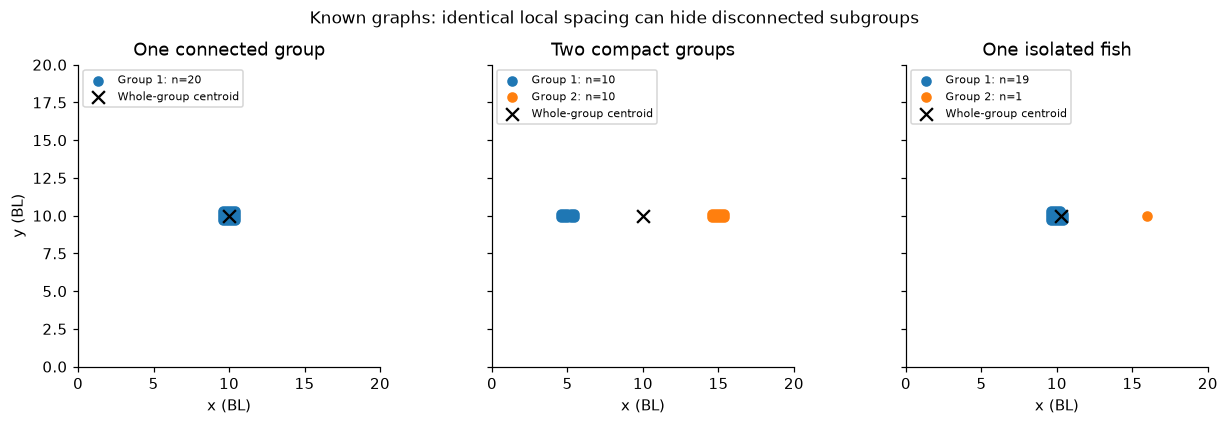

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True, sharey=True)
for axis, (name, positions, _) in zip(axes, known_states):
    components = graph_components(positions, SOCIAL_RANGE)
    for group_number, indices in enumerate(components):
        points = positions[indices]
        axis.scatter(points[:, 0], points[:, 1], s=35, label=f"Group {group_number + 1}: n={len(indices)}")
    centroid = positions.mean(axis=0)
    axis.scatter(*centroid, marker="x", color="black", s=70, label="Whole-group centroid")
    axis.set(title=name, xlabel="x (BL)", xlim=(0, 20), ylim=(0, 20), aspect="equal")
    axis.legend(fontsize=7, loc="upper left")
axes[0].set_ylabel("y (BL)")
fig.suptitle("Known graphs: identical local spacing can hide disconnected subgroups", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "01_known_connectivity_states.png", dpi=180, bbox_inches="tight")
plt.show()


## Reproduce the original ten seeds without changing the model

Each run lasts 62.5 seconds, corresponding to 500 updates at `dt=0.125`. The initial state is retained, so each enriched frame has 501 records. We save complete group frames for reproducible downstream comparisons in `data/baseline_seed_0.csv` through `data/baseline_seed_9.csv`.

The summary uses the final 12.5 seconds, **Time > 50 s**, so it contains 100 post-update records per seed. A persistent episode is defined as consecutive fragmented post-update intervals totalling at least 2.5 seconds; that duration is a diagnostic convention, not a biological constant.


In [4]:
baseline_models, baseline_frames, baseline_agents = {}, {}, {}
summary_rows = []
for seed in range(10):
    model, frame, agents = run_case(seed=seed, duration=DURATION_S)
    assert len(frame) == 501 and model.steps == 500
    np.testing.assert_allclose(frame["Time"], np.arange(501) * 0.125)
    assert frame["NumberOfGroups"].between(1, 20).all()
    assert frame["LargestGroupSize"].between(1, 20).all()
    np.testing.assert_allclose(frame["LargestGroupFraction"], frame["LargestGroupSize"] / 20)
    assert (frame["SecondLargestGroupSize"] <= frame["LargestGroupSize"]).all()
    assert frame.loc[frame["NumberOfGroups"] == 1, "SecondLargestGroupSize"].eq(0).all()
    final_positions = np.array([fish.position for fish in model.agents])
    final_sizes = [len(group) for group in graph_components(final_positions, SOCIAL_RANGE)]
    assert frame["ComponentSizes"].iloc[-1] == "+".join(map(str, final_sizes))
    baseline_models[seed], baseline_frames[seed], baseline_agents[seed] = model, frame, agents
    frame.to_csv(DATA_DIR / f"baseline_seed_{seed}.csv", index_label="Step")
    summary_rows.append({"Seed": seed, "Speed": 1.0, "dt": 0.125, **summarize_case(frame)})

baseline_summary = pd.DataFrame(summary_rows)
baseline_summary.to_csv(DATA_DIR / "01_connectivity_case_summary.csv", index=False)
baseline_summary[[
    "Seed", "FirstConnectedTime_s", "FinalGroups", "FinalComponentSizes",
    "FinalLargestGroupFraction", "ConnectedTimeFraction", "PersistentSplitEvents",
    "LateMeanNND", "LateMeanDistanceToCentroid", "LatePolarization", "LateRotation",
]]


,Seed,FirstConnectedTime_s,FinalGroups,FinalComponentSizes,FinalLargestGroupFraction,ConnectedTimeFraction,PersistentSplitEvents,LateMeanNND,LateMeanDistanceToCentroid,LatePolarization,LateRotation
0,0,NaN,2,10+10,0.50,0.000,0,0.583967,9.864650,0.456352,0.431871
1,1,0.000,1,20,1.00,1.000,0,0.574434,1.137601,0.942320,0.057658
2,2,NaN,2,19+1,0.95,0.000,0,1.268691,1.970379,0.943252,0.470440
3,3,14.250,1,20,1.00,0.774,0,0.585040,1.168168,0.968058,0.018381
4,4,47.000,1,20,1.00,0.250,0,0.597050,1.199970,0.938920,0.029682
5,5,12.500,1,20,1.00,0.802,0,0.563832,1.099655,0.983182,0.007040
6,6,21.250,1,20,1.00,0.662,0,0.560677,1.087089,0.937952,0.031576
7,7,7.625,1,20,1.00,0.880,0,0.574599,1.136667,0.932686,0.040157
8,8,14.125,1,20,1.00,0.776,0,0.593075,1.122053,0.964578,0.026352
9,9,56.000,1,20,1.00,0.106,0,0.582184,2.832755,0.656086,0.347806


## Verify that the diagnostics are observers

The enriched measurements are computed from completed DataCollector records. We also rerun seed 0 using the plain shared model, without invoking connectivity diagnostics, and compare its complete original group and individual records. Matching these histories checks that measuring connectivity did not steer a fish or consume random draws.


In [5]:
plain_model = GoldenShinersModel(seed=0)
for _ in range(500):
    plain_model.step()
plain_group = plain_model.datacollector.get_model_vars_dataframe()
plain_agents = plain_model.datacollector.get_agent_vars_dataframe()
pd.testing.assert_frame_equal(baseline_frames[0][plain_group.columns], plain_group, check_exact=True)
pd.testing.assert_frame_equal(baseline_agents[0], plain_agents, check_exact=True)
print("Observer check passed: all 501 group records and 10020 individual records exactly match the plain model.")


Observer check passed: all 501 group records and 10020 individual records exactly match the plain model.


## Connectivity over time and its relation to spacing

Seeds 0 and 2 are highlighted because their previously observed final states were fragmented. Seed 1 supplies a final-connected comparison. The other seven seeds remain visible in grey.

A point in the lower-right part of the local-spacing scatter can have a small nearest-neighbour distance but a small largest-group fraction. Global spread provides additional information, but it does not identify the number or sizes of the disconnected components by itself.


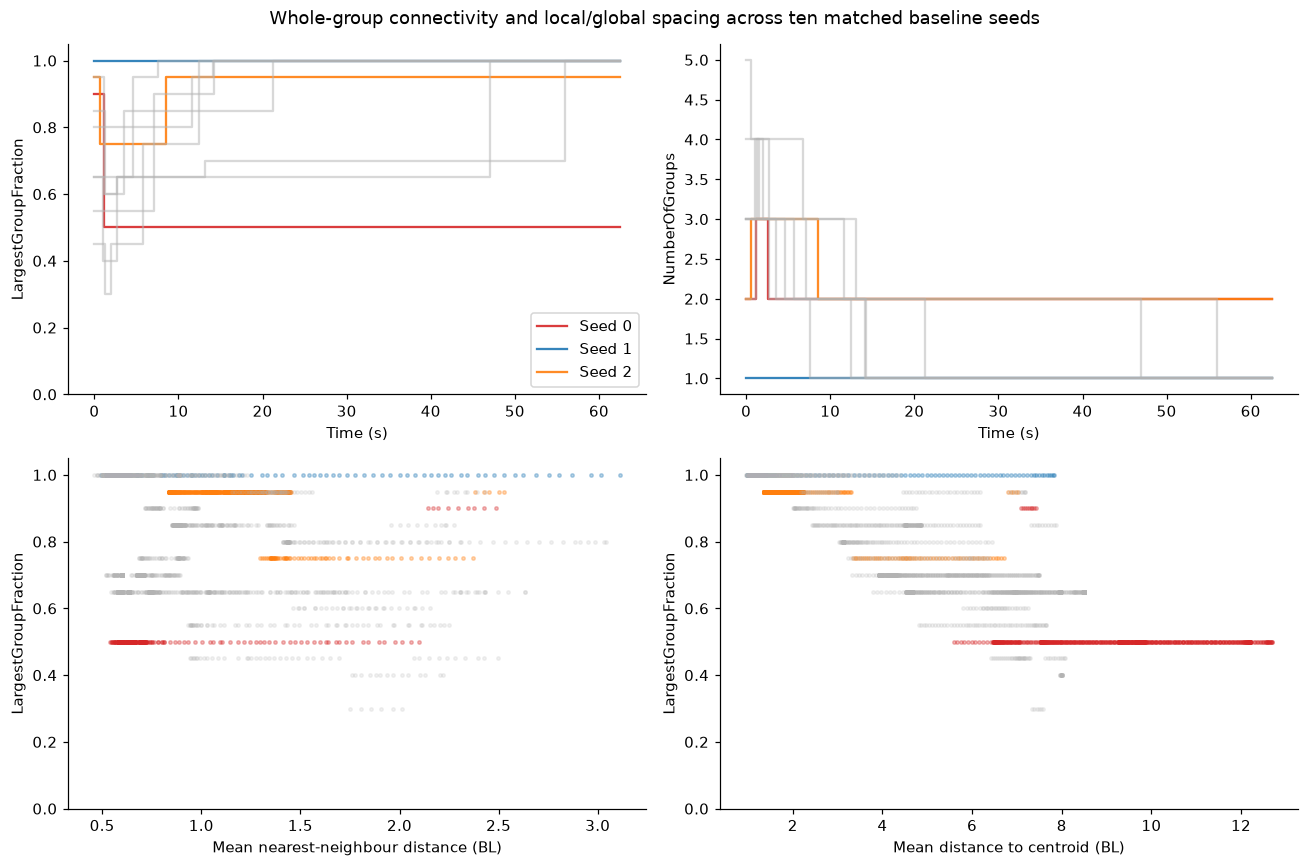

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for seed, frame in baseline_frames.items():
    color = COLORS.get(seed, "0.7")
    alpha = 0.9 if seed in COLORS else 0.5
    label = f"Seed {seed}" if seed in COLORS else None
    axes[0, 0].step(frame["Time"], frame["LargestGroupFraction"], where="post", color=color, alpha=alpha, label=label)
    axes[0, 1].step(frame["Time"], frame["NumberOfGroups"], where="post", color=color, alpha=alpha)
    axes[1, 0].scatter(frame["MeanNND"], frame["LargestGroupFraction"], s=5, color=color, alpha=alpha * 0.35)
    axes[1, 1].scatter(frame["MeanDistanceToCentroid"], frame["LargestGroupFraction"], s=5, color=color, alpha=alpha * 0.35)
axes[0, 0].set(xlabel="Time (s)", ylabel="LargestGroupFraction", ylim=(0, 1.05))
axes[0, 1].set(xlabel="Time (s)", ylabel="NumberOfGroups", ylim=(0.8, None))
axes[1, 0].set(xlabel="Mean nearest-neighbour distance (BL)", ylabel="LargestGroupFraction", ylim=(0, 1.05))
axes[1, 1].set(xlabel="Mean distance to centroid (BL)", ylabel="LargestGroupFraction", ylim=(0, 1.05))
axes[0, 0].legend(loc="lower right")
fig.suptitle("Whole-group connectivity and local/global spacing across ten matched baseline seeds")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "01_connectivity_spacing.png", dpi=180, bbox_inches="tight")
plt.show()


## Compare connectivity with polarization and rotation

Polarization and rotation describe the directional order of the entire population, following [Tunstrøm et al. (2013)](https://doi.org/10.1371/journal.pcbi.1002915). Connectivity describes a different structural property. Separate aligned subgroups can have high global polarization; oppositely moving subgroups can instead cancel that average. Neither outcome alone identifies a connected school.


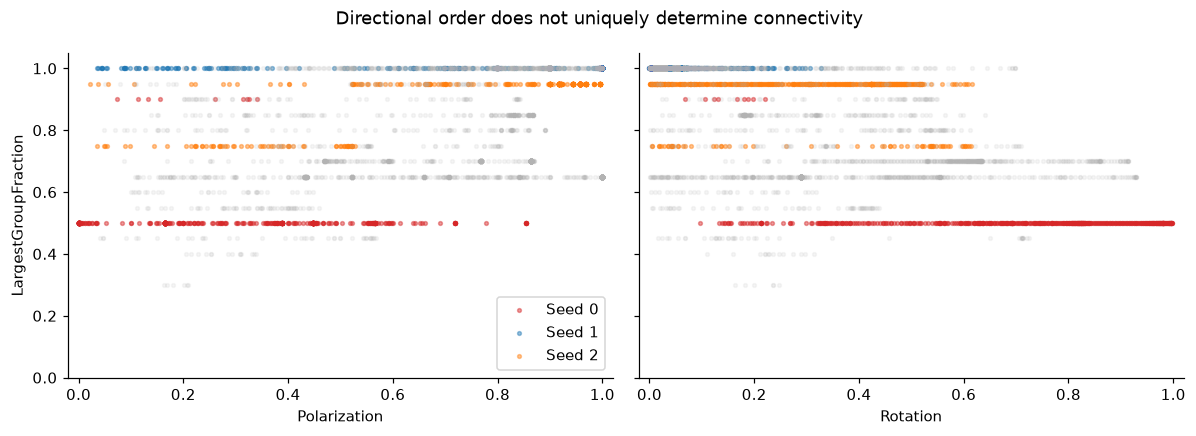

,Seed,LateMeanLargestGroupFraction,LateMeanNND,LateMeanDistanceToCentroid,LatePolarization
0,0,0.50,0.583967,9.864650,0.456352
1,1,1.00,0.574434,1.137601,0.942320
2,2,0.95,1.268691,1.970379,0.943252


**Executed result.** 8 of the ten runs end as one connected component. The final component sizes for seeds 0 and 2 are **10+10** and **19+1**, respectively. The table compares their late local spacing and global spread with seed 1. The graph adds information that the nearest-neighbour average does not contain.

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for seed, frame in baseline_frames.items():
    color = COLORS.get(seed, "0.7")
    alpha = 0.45 if seed in COLORS else 0.12
    label = f"Seed {seed}" if seed in COLORS else None
    axes[0].scatter(frame["Polarization"], frame["LargestGroupFraction"], s=6, color=color, alpha=alpha, label=label)
    axes[1].scatter(frame["Rotation"], frame["LargestGroupFraction"], s=6, color=color, alpha=alpha)
axes[0].set(xlabel="Polarization", ylabel="LargestGroupFraction", xlim=(-0.02, 1.02), ylim=(0, 1.05))
axes[1].set(xlabel="Rotation", xlim=(-0.02, 1.02))
axes[0].legend(loc="lower right")
fig.suptitle("Directional order does not uniquely determine connectivity")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "01_connectivity_order_parameters.png", dpi=180, bbox_inches="tight")
plt.show()

final_groups = baseline_summary.set_index("Seed")["FinalComponentSizes"].to_dict()
fragmented_final = baseline_summary.loc[baseline_summary["FinalGroups"] > 1, "Seed"].tolist()
late_comparison = baseline_summary.loc[baseline_summary["Seed"].isin([0, 1, 2]), [
    "Seed", "LateMeanLargestGroupFraction", "LateMeanNND", "LateMeanDistanceToCentroid", "LatePolarization",
]]
display(late_comparison)
display(Markdown(
    f"**Executed result.** {10 - len(fragmented_final)} of the ten runs end as one connected component. "
    f"The final component sizes for seeds 0 and 2 are **{final_groups[0]}** and **{final_groups[2]}**, respectively. "
    "The table compares their late local spacing and global spread with seed 1. "
    "The graph adds information that the nearest-neighbour average does not contain."
))


## Interpretation and hand-off

The known-state tests establish that `NumberOfGroups`, `LargestGroupSize`, `LargestGroupFraction`, and `SecondLargestGroupSize` distinguish one school, balanced subgroups and isolated fish. The seeded runs reproduce the baseline while leaving its dynamics unchanged.

These measurements alone cannot decide whether disconnection is an emergent consequence of finite social range, an effect of wall interactions, or a numerical effect. They identify **what happened**, not its cause. The next notebook separates initial disconnection from a persistent split after an observed connected state, then locates the relevant events in space and time.

Saved evidence: all ten enriched group CSVs, `data/01_connectivity_case_summary.csv`, and three figures in `figures/`. Consecutive timestep samples are correlated; the scatterplots contain repeated measurements, not thousands of independent experimental replicates.


### Actual baseline finding: failure to assemble, rather than breakup after whole-group cohesion

Eight of the ten runs finish connected. Seeds **0 and 2 never contain one connected component at any recorded time** during the 62.5-second observation. Seed 0 begins as **18 + 2** and ends as **10 + 10**; seed 2 begins and ends as **19 + 1**. Seed 1 is connected from the initial state onward.

The remaining seven seeds first assemble at 7.625–56.000 seconds. Across all ten runs there are **zero persistent splits from an observed connected state**; direct inspection also finds zero shorter fragmented records after first whole-group cohesion. Thus the unresolved baseline result is incomplete or delayed **whole-population assembly**, rather than observed breakup of a previously connected 20-fish school.

This distinction does not imply fixed subgroup identities: seed 0 changes from 18 + 2 to 10 + 10 while the whole population remains disconnected. Component fission, merging or fish exchange can occur within such an episode. The present graph summaries do not track those identities or establish why reconnection fails.
